# Triplet TORP on joint-RP RQA vectors

Closeness = similar recurrence *relationships*. For a triplet (a, b, c), each sliding window gives three joint RPs
(ab, ac, bc); the RQA of each is a feature vector, and
$T_{ijk} = d(f^{ab}_i, f^{ac}_j) + d(f^{ab}_i, f^{bc}_k) + d(f^{ac}_j, f^{bc}_k)$.
Small $T_{www}$: in window w the three pairs are linked in the same way. Joint RR is kept (it carries the
dependence); each feature is taken as excess over a null pair with the second series shifted by one window.

## 1. Setup

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

sys.path.insert(0, str(Path("../../src").resolve()))
from recplay.rqa import rqa
from recplay.recurrence import threshold_by_rate
from recplay.torp import perimeter_tensor, same_time_stats, whitening_matrix
from recplay.windowed import euclidean_distance, rqa_frame, window_z

PRICES = Path("../../data/raw/yahoo/triplet_prices_2015_2024.csv")
OUT = Path("../tables/torp_rqa_joint")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

M, TAU, THEILER = 3, 1, 1      # same embedding as 01_triplet_perimeter
W, STEP = 250, 10              # one trading year per window, a new window every two weeks
RR_SERIES = 0.15               # per-series rate; joint RPs of independent series then recur at ~2.25 %
RR_TENSOR = 0.05               # fixed rate over all entries of the TORP
COVERAGE_MIN = 0.95            # a feature defined in fewer windows than this is dropped
SHIFT = W                      # null pair: second series shifted by one window (circularly)
FEATURES = ["RR", "DET", "L", "ENTR", "LAM", "K2_lines"]

TRIPLETS = {
    "none":            ("TIP", "UNG", "XLP"),
    "mid +":           ("FXY", "GLD", "TIP"),
    "mid + (risk)":    ("EWZ", "FXI", "HYG"),
    "high +":          ("EFA", "IWM", "SPY"),
    "one-out +":       ("GLD", "SLV", "UNG"),
    "mid mixed-sign":  ("XLE", "XLP", "^VIX"),
    "high mixed-sign": ("IWM", "SPY", "^VIX"),
    "one-out −":       ("EFA", "UNG", "^VIX"),
}
TICKERS = sorted({t for tr in TRIPLETS.values() for t in tr})

## 2. Data

In [2]:
if not PRICES.exists():
    raise FileNotFoundError(f"{PRICES} is written by 01_triplet_perimeter; run that notebook first")
prices = pd.read_csv(PRICES, index_col=0, parse_dates=True)
returns = np.log(prices).diff().iloc[1:].dropna()
full_r = returns.corr()

def triplet_pairs(tr):
    return [(tr[0], tr[1]), (tr[0], tr[2]), (tr[1], tr[2])]

pattern = pd.DataFrame({name: {"mean_r": np.mean([full_r.loc[p] for p in triplet_pairs(tr)]),
                               "mean_abs_r": np.mean([abs(full_r.loc[p]) for p in triplet_pairs(tr)]),
                               "abs_r_spread": np.ptp([abs(full_r.loc[p]) for p in triplet_pairs(tr)])}
                        for name, tr in TRIPLETS.items()}).T
print(f"{len(returns)} daily returns, {returns.index[0].date()} to {returns.index[-1].date()}")
pattern.round(2)

2515 daily returns, 2015-01-05 to 2024-12-31


,mean_r,mean_abs_r,abs_r_spread
none,0.03,0.03,0.03
mid +,0.41,0.41,0.09
mid + (risk),0.48,0.48,0.08
high +,0.84,0.84,0.07
one-out +,0.27,0.27,0.77
mid mixed-sign,-0.18,0.46,0.08
high mixed-sign,-0.17,0.75,0.22
one-out −,-0.21,0.27,0.60


## 3. Windowed RQA

In [3]:
PAIRS = sorted({tuple(sorted(p)) for tr in TRIPLETS.values() for p in triplet_pairs(tr)})
data = returns.copy()
for t in TICKERS:
    data[f"{t}|null"] = np.roll(returns[t].to_numpy(), SHIFT)
series = {c: c for c in data.columns}
joints = {}
for a, b in PAIRS:
    joints[f"{a}&{b}"] = (a, b)
    joints[f"{a}&{b}|null"] = (a, f"{b}|null")
frame = rqa_frame(data, series, joints, W, M, TAU, RR_SERIES, euclidean_distance, THEILER, step=STEP)
raw = {p: frame[[f"{p[0]}&{p[1]}_{k}" for k in FEATURES]].set_axis(FEATURES, axis=1) for p in PAIRS}
null = {p: frame[[f"{p[0]}&{p[1]}|null_{k}" for k in FEATURES]].set_axis(FEATURES, axis=1) for p in PAIRS}
excess = {p: raw[p] - null[p] for p in PAIRS}
print(f"{len(frame)} windows ending {frame.index[0].date()} to {frame.index[-1].date()}, {len(PAIRS)} pairs")
pd.DataFrame({"joint RR": {p: raw[p]["RR"].mean() for p in PAIRS}, "null RR": {p: null[p]["RR"].mean() for p in PAIRS},
              "excess RR": {p: excess[p]["RR"].mean() for p in PAIRS}, "full-period r": {p: full_r.loc[p] for p in PAIRS}}).round(4)

227 windows ending 2015-12-30 to 2024-12-23, 23 pairs


joint RR  null RR  excess RR  full-period r
EFA IWM     0.0522   0.0207     0.0315         0.7951
    SPY     0.0641   0.0203     0.0438         0.8558
    UNG     0.0242   0.0207     0.0035         0.0798
    ^VIX    0.0455   0.0221     0.0233        -0.6630
EWZ FXI     0.0343   0.0229     0.0114         0.4527
    HYG     0.0345   0.0218     0.0127         0.5285
FXI HYG     0.0347   0.0212     0.0134         0.4633
FXY GLD     0.0364   0.0224     0.0140         0.4494
    TIP     0.0338   0.0220     0.0118         0.3643
GLD SLV     0.0603   0.0224     0.0379         0.7773
    TIP     0.0333   0.0230     0.0102         0.4091
    UNG     0.0237   0.0202     0.0035         0.0059
IWM SPY     0.0688   0.0215     0.0473         0.8684
    ^VIX    0.0459   0.0226     0.0234        -0.6527
SLV UNG     0.0239   0.0206     0.0033         0.0242
SPY ^VIX    0.0593   0.0224     0.0370        -0.7266
TIP UNG     0.0228   0.0212     0.0016         0.0227
    XLP     0.0265   0.0245     0.0020         0.0219
UNG XLP     0.0241   0.0219     0.0021         0.0563
    ^VIX    0.0226   0.0236    -0.0011        -0.0604
XLE XLP     0.0317   0.0215     0.0101         0.4236
    ^VIX    0.0324   0.0234     0.0090        -0.4465
XLP ^VIX    0.0353   0.0218     0.0135        -0.5041

## 4. Sign invariance check

In [4]:
x = returns["SPY"].to_numpy()
end = W - 1
plus = rqa(threshold_by_rate(euclidean_distance(window_z(x, end, W), M, TAU), RR_SERIES, THEILER))
minus = rqa(threshold_by_rate(euclidean_distance(window_z(-x, end, W), M, TAU), RR_SERIES, THEILER))
assert all(np.isclose(plus[k], minus[k], equal_nan=True) for k in plus)
print("RQA of x and -x agree: the features cannot see the sign of a series, so VIX needs no flip")

RQA of x and -x agree: the features cannot see the sign of a series, so VIX needs no flip


## 5. Normalisation and whitening

In [5]:
def prepare(vecs, label):
    """Pooled coverage rule, median fill, pooled z-score and whitening over every window of every key."""
    pooled = pd.concat(vecs.values())
    coverage = pooled.notna().mean()
    keep = [f for f in FEATURES if coverage[f] >= COVERAGE_MIN]
    filled = {k: v[keep].fillna(pooled[keep].median()) for k, v in vecs.items()}
    pooled = pd.concat(filled.values())
    mu, sd = pooled.mean(), pooled.std()
    z = {k: ((v - mu) / sd).to_numpy() for k, v in filled.items()}
    Wm = whitening_matrix(np.vstack(list(z.values())))
    info = {"set": label, "kept": ", ".join(keep), "dropped": ", ".join(f for f in FEATURES if f not in keep) or "none",
            "filled cells": int(sum(v[keep].isna().sum().sum() for v in vecs.values())),
            **{f"coverage {f}": coverage[f] for f in FEATURES}}
    return {"z": z, "white": {k: v @ Wm for k, v in z.items()}, "corr": pooled.corr(), "info": info}

In [6]:
sets = {"excess": prepare(excess, "excess over null pair"), "raw": prepare(raw, "raw joint")}
display(pd.DataFrame([s["info"] for s in sets.values()]).set_index("set").round(3))
sets["excess"]["corr"].round(2)

,kept,dropped,filled cells,coverage RR,coverage DET,coverage L,coverage ENTR,coverage LAM,coverage K2_lines
set,,,,,,,,,
excess over null pair,"RR, DET, L, ENTR, LAM, K2_lines",none,0,1.0,1.0,1.0,1.0,1.0,1.0
raw joint,"RR, DET, L, ENTR, LAM, K2_lines",none,0,1.0,1.0,1.0,1.0,1.0,1.0


,RR,DET,L,ENTR,LAM,K2_lines
RR,1.00,0.79,0.74,0.72,0.63,-0.65
DET,0.79,1.00,0.78,0.81,0.75,-0.81
L,0.74,0.78,1.00,0.97,0.75,-0.86
ENTR,0.72,0.81,0.97,1.00,0.74,-0.92
LAM,0.63,0.75,0.75,0.74,1.00,-0.69
K2_lines,-0.65,-0.81,-0.86,-0.92,-0.69,1.00


## 6. TORP per triplet

In [7]:
VARIANTS = {"mahalanobis, excess": ("excess", "white"), "euclidean, excess": ("excess", "z"), "mahalanobis, raw": ("raw", "white")}
def keys_of(tr):
    return [tuple(sorted(p)) for p in triplet_pairs(tr)]

In [8]:
rows, diagonals = [], {}
for name, tr in TRIPLETS.items():
    for variant, (set_name, kind) in VARIANTS.items():
        states = [sets[set_name][kind][k] for k in keys_of(tr)]
        T = perimeter_tensor(*states)
        idx = np.arange(len(T))
        diagonals[(name, variant)] = T[idx, idx, idx] / T.mean(dtype=np.float64)
        rows.append({"category": name, "variant": variant, "a": tr[0], "b": tr[1], "c": tr[2], **pattern.loc[name].to_dict(),
                     **same_time_stats(T, RR_TENSOR)})
        del T
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "summary.csv", index=False)
pd.DataFrame({f"{n} | {v}": d for (n, v), d in diagonals.items()}, index=frame.index).to_csv(OUT / "same_window_dissimilarity.csv")
summary.pivot(index="category", columns="variant", values=["sync_ratio", "sync_enrichment"]).loc[list(TRIPLETS)].round(3)

sync_ratio                                       \
variant         euclidean, excess mahalanobis, excess mahalanobis, raw   
category                                                                 
none                        0.905               0.960            0.979   
mid +                       0.858               0.911            0.880   
mid + (risk)                0.848               0.924            0.828   
high +                      0.605               0.685            0.620   
one-out +                   0.934               0.985            0.936   
mid mixed-sign              0.820               0.901            0.800   
high mixed-sign             0.742               0.817            0.774   
one-out −                   0.977               0.963            0.924   

                  sync_enrichment                                       
variant         euclidean, excess mahalanobis, excess mahalanobis, raw  
category                                                                
none                        2.555               2.203            0.705  
mid +                       2.115               2.467            1.762  
mid + (risk)                2.026               2.115            3.877  
high +                      3.612               4.670            5.991  
one-out +                   1.145               1.322            1.410  
mid mixed-sign              1.762               1.762            3.172  
high mixed-sign             1.498               3.172            5.022  
one-out −                   1.322               1.938            1.762

## 7. Relation to the correlation pattern

In [9]:
rel = []
for variant, g in summary.groupby("variant", sort=False):
    for col in ["mean_r", "mean_abs_r", "abs_r_spread"]:
        rel.append({"variant": variant, "against": col, "spearman (n = 8 triplets)": spearmanr(g[col], g["sync_ratio"]).statistic})
rel = pd.DataFrame(rel)
rel.to_csv(OUT / "relation_to_correlation.csv", index=False)
rel.pivot(index="variant", columns="against", values="spearman (n = 8 triplets)").round(2)

against,abs_r_spread,mean_abs_r,mean_r
variant,,,
"euclidean, excess",0.45,-0.90,-0.40
"mahalanobis, excess",0.43,-0.83,-0.29
"mahalanobis, raw",0.17,-0.95,-0.26


In [10]:
pair_dep = pd.DataFrame({"abs_r": {p: abs(full_r.loc[p]) for p in PAIRS}, "r": {p: full_r.loc[p] for p in PAIRS},
                         "excess_RR": {p: excess[p]["RR"].mean() for p in PAIRS}})
pair_dep.to_csv(OUT / "pair_dependence.csv")
print(f"Spearman over {len(PAIRS)} pairs: excess joint RR vs |r| = {spearmanr(pair_dep.abs_r, pair_dep.excess_RR).statistic:.2f}, "
      f"vs signed r = {spearmanr(pair_dep.r, pair_dep.excess_RR).statistic:.2f}")

Spearman over 23 pairs: excess joint RR vs |r| = 0.94, vs signed r = 0.36


## 8. Figures

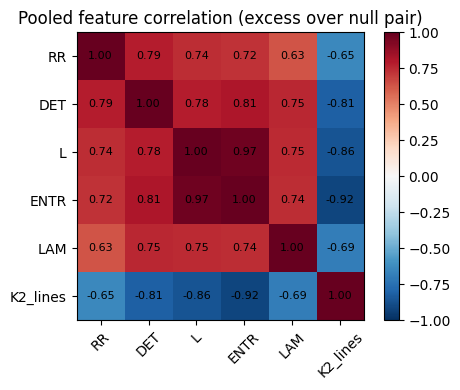

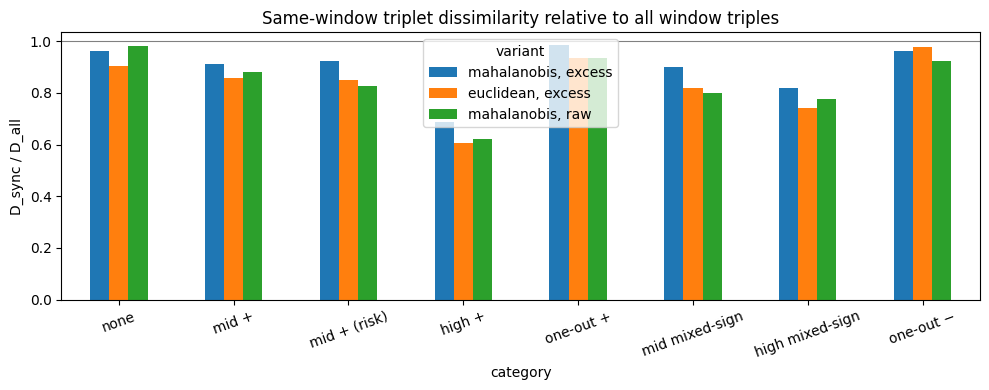

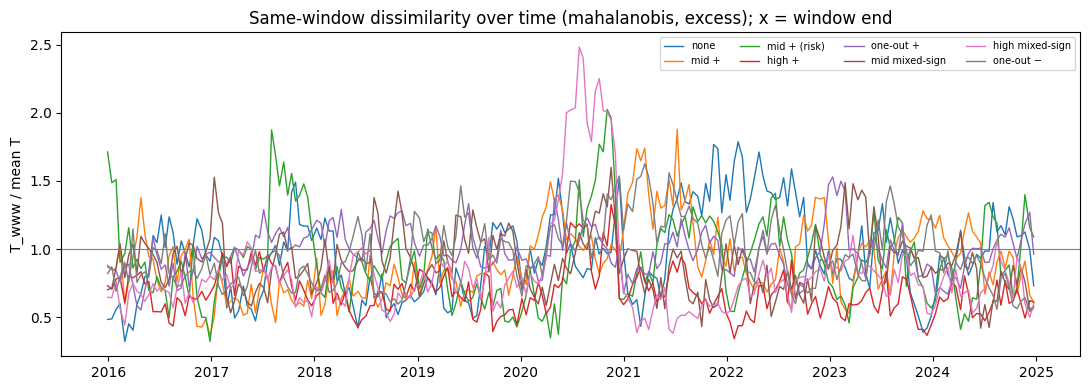

In [11]:
first = next(iter(sets.values()))
fig, ax = plt.subplots(figsize=(5, 4))
c = first["corr"]
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(c)), c.columns, rotation=45); ax.set_yticks(range(len(c)), c.index)
for i in range(len(c)):
    for j in range(len(c)):
        ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title(f"Pooled feature correlation ({first['info']['set']})")
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.savefig(FIG / "feature_correlation.png", dpi=150); plt.show()

piv = summary.pivot(index="category", columns="variant", values="sync_ratio").loc[list(TRIPLETS), list(VARIANTS)]
ax = piv.plot.bar(figsize=(10, 4), rot=20)
ax.axhline(1, color="grey", lw=0.8); ax.set_ylabel("D_sync / D_all"); ax.set_title("Same-window triplet dissimilarity relative to all window triples")
plt.tight_layout(); plt.savefig(FIG / "sync_ratio_by_category.png", dpi=150); plt.show()

primary = list(VARIANTS)[0]
fig, ax = plt.subplots(figsize=(11, 4))
for name in TRIPLETS:
    ax.plot(frame.index, diagonals[(name, primary)], label=name, lw=1)
ax.axhline(1, color="grey", lw=0.8)
ax.set(ylabel="T_www / mean T", title=f"Same-window dissimilarity over time ({primary}); x = window end")
ax.legend(fontsize=7, ncol=4); plt.tight_layout(); plt.savefig(FIG / "same_window_over_time.png", dpi=150); plt.show()

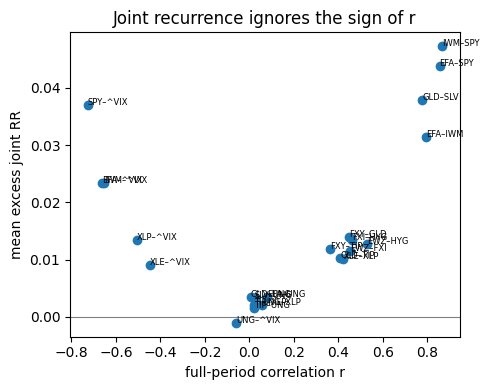

In [12]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(pair_dep.r, pair_dep.excess_RR)
for p, row in pair_dep.iterrows():
    ax.annotate(f"{p[0]}–{p[1]}", (row.r, row.excess_RR), fontsize=6)
ax.axhline(0, color="grey", lw=0.8)
ax.set(xlabel="full-period correlation r", ylabel="mean excess joint RR", title="Joint recurrence ignores the sign of r")
plt.tight_layout(); plt.savefig(FIG / "excess_joint_rr_vs_r.png", dpi=150); plt.show()

## 9. Findings

Same windows and settings as `02_individual_rqa_torp` (227 windows, W = 250, step 10, per-series RR = 15 %, m = 3, τ = 1). Features RR, DET, L, ENTR, LAM, K2_lines of each pairwise joint RP, all defined in every window; primary variant: excess over a null pair (second series shifted 250 days), pooled z-score, Mahalanobis.

1. **Joint recurrence measures dependence strength without its sign.** Over 23 pairs, mean excess joint RR has Spearman 0.94 with |r| and 0.36 with signed r. SPY–VIX (r = −0.73) has an excess of 0.037, close to GLD–SLV (r = 0.78, 0.038). Uncorrelated pairs sit near 0 (−0.001 to 0.004), so the shifted-series null works as a zero point.
2. **The joint features are also highly correlated** (L–ENTR 0.97, ENTR–K2 −0.92, RR–DET 0.79), so whitening matters here too.
3. **Same-window closeness of the three relationships tracks mean |r|, not how uneven the pairs are.** Spearman over 8 triplets: mean |r| −0.83 (excess, Mahalanobis), −0.95 (raw); spread of |r| only +0.43 / +0.17. Lowest ratio: high + 0.69; highest: one-out + 0.99, one-out − 0.96, but "none" is close behind at 0.96. This contradicts the prediction that "none" (three equally weak pairs) would look as close as high +: weak pairs' excess features are mostly noise, so in the same window they are not more alike than across windows.
4. **High mixed-sign behaves like a dependent triplet** (0.82, between mid and high +), again because joint RPs are sign-blind.
5. **Raw vs excess.** Without the null correction the measure follows |r| even more closely (−0.95) and the 5 % enrichment rises with dependence (high + 6.0×, high mixed-sign 5.0×, none 0.7×), i.e. raw joint features mix dependence with each series' own regularity.

**Meaning.** Built on joint-RP RQA, the TORP's same-window diagonal mainly says "these three pairs are all strongly linked right now". It does recover the dependence that the returns TORP of `01` missed for anti-correlated series, but within this design it is close to a sign-blind summary of the three |r| values, not a separate measure of how evenly dependence is spread.